In [1]:
import numpy as np

import matplotlib.pyplot as plt
plt.rcParams.update({
    "text.usetex": True,
    "font.size": 16,
    "font.family": "serif",
})

from LogicalQ.Estimators import build_gadgets_library, compute_gadget_costs
from LogicalQ.Library.HardwareModels import hardware_model_Quantinuum_H2_1

In [2]:
gadgets_library = build_gadgets_library(
    min_depth=2, max_depth=4+1, step_depth=1,
    min_n_qubits=1, max_n_qubits=2+1, step_n_qubits=1
)

gadgets_library, gadget_infidelities, gadget_costs = compute_gadget_costs(
    gadgets_library=gadgets_library,
    backend="aer_simulator", hardware_model=hardware_model_Quantinuum_H2_1
)

In [3]:
gadgets_library

{2: {1: [((qiskit.circuit.library.standard_gates.h.HGate, (0,)),
    (qiskit.circuit.library.standard_gates.x.XGate, (0,))),
   ((qiskit.circuit.library.standard_gates.h.HGate, (0,)),
    (qiskit.circuit.library.standard_gates.y.YGate, (0,))),
   ((qiskit.circuit.library.standard_gates.h.HGate, (0,)),
    (qiskit.circuit.library.standard_gates.z.ZGate, (0,))),
   ((qiskit.circuit.library.standard_gates.h.HGate, (0,)),
    (qiskit.circuit.library.standard_gates.s.SGate, (0,))),
   ((qiskit.circuit.library.standard_gates.h.HGate, (0,)),
    (qiskit.circuit.library.standard_gates.t.TGate, (0,))),
   ((qiskit.circuit.library.standard_gates.x.XGate, (0,)),
    (qiskit.circuit.library.standard_gates.h.HGate, (0,))),
   ((qiskit.circuit.library.standard_gates.x.XGate, (0,)),
    (qiskit.circuit.library.standard_gates.y.YGate, (0,))),
   ((qiskit.circuit.library.standard_gates.x.XGate, (0,)),
    (qiskit.circuit.library.standard_gates.z.ZGate, (0,))),
   ((qiskit.circuit.library.standard_gates

In [4]:
gadget_infidelities

{2: {1: {((qiskit.circuit.library.standard_gates.h.HGate, (0,)),
    (qiskit.circuit.library.standard_gates.x.XGate,
     (0,))): (2.069516744951372e-05,
    1.814382911169421e-05),
   ((qiskit.circuit.library.standard_gates.h.HGate, (0,)),
    (qiskit.circuit.library.standard_gates.y.YGate,
     (0,))): (2.0695167449291674e-05,
    1.814382911169421e-05),
   ((qiskit.circuit.library.standard_gates.h.HGate, (0,)),
    (qiskit.circuit.library.standard_gates.z.ZGate,
     (0,))): (2.069516744951372e-05,
    2.8349829111373737e-05),
   ((qiskit.circuit.library.standard_gates.h.HGate, (0,)),
    (qiskit.circuit.library.standard_gates.s.SGate,
     (0,))): (2.069516744951372e-05,
    2.8349829111373737e-05),
   ((qiskit.circuit.library.standard_gates.h.HGate, (0,)),
    (qiskit.circuit.library.standard_gates.t.TGate,
     (0,))): (2.069516744951372e-05,
    2.8349829111373737e-05),
   ((qiskit.circuit.library.standard_gates.x.XGate, (0,)),
    (qiskit.circuit.library.standard_gates.h.HGate,

In [5]:
gadget_costs

{2: {1: {((qiskit.circuit.library.standard_gates.h.HGate, (0,)),
    (qiskit.circuit.library.standard_gates.x.XGate,
     (0,))): 2.5513383378195087e-06,
   ((qiskit.circuit.library.standard_gates.h.HGate, (0,)),
    (qiskit.circuit.library.standard_gates.y.YGate,
     (0,))): 2.551338337597464e-06,
   ((qiskit.circuit.library.standard_gates.h.HGate, (0,)),
    (qiskit.circuit.library.standard_gates.z.ZGate,
     (0,))): -7.654661661860018e-06,
   ((qiskit.circuit.library.standard_gates.h.HGate, (0,)),
    (qiskit.circuit.library.standard_gates.s.SGate,
     (0,))): -7.654661661860018e-06,
   ((qiskit.circuit.library.standard_gates.h.HGate, (0,)),
    (qiskit.circuit.library.standard_gates.t.TGate,
     (0,))): -7.654661661860018e-06,
   ((qiskit.circuit.library.standard_gates.x.XGate, (0,)),
    (qiskit.circuit.library.standard_gates.h.HGate,
     (0,))): -1.199488286474093e-10,
   ((qiskit.circuit.library.standard_gates.x.XGate, (0,)),
    (qiskit.circuit.library.standard_gates.y.YGa

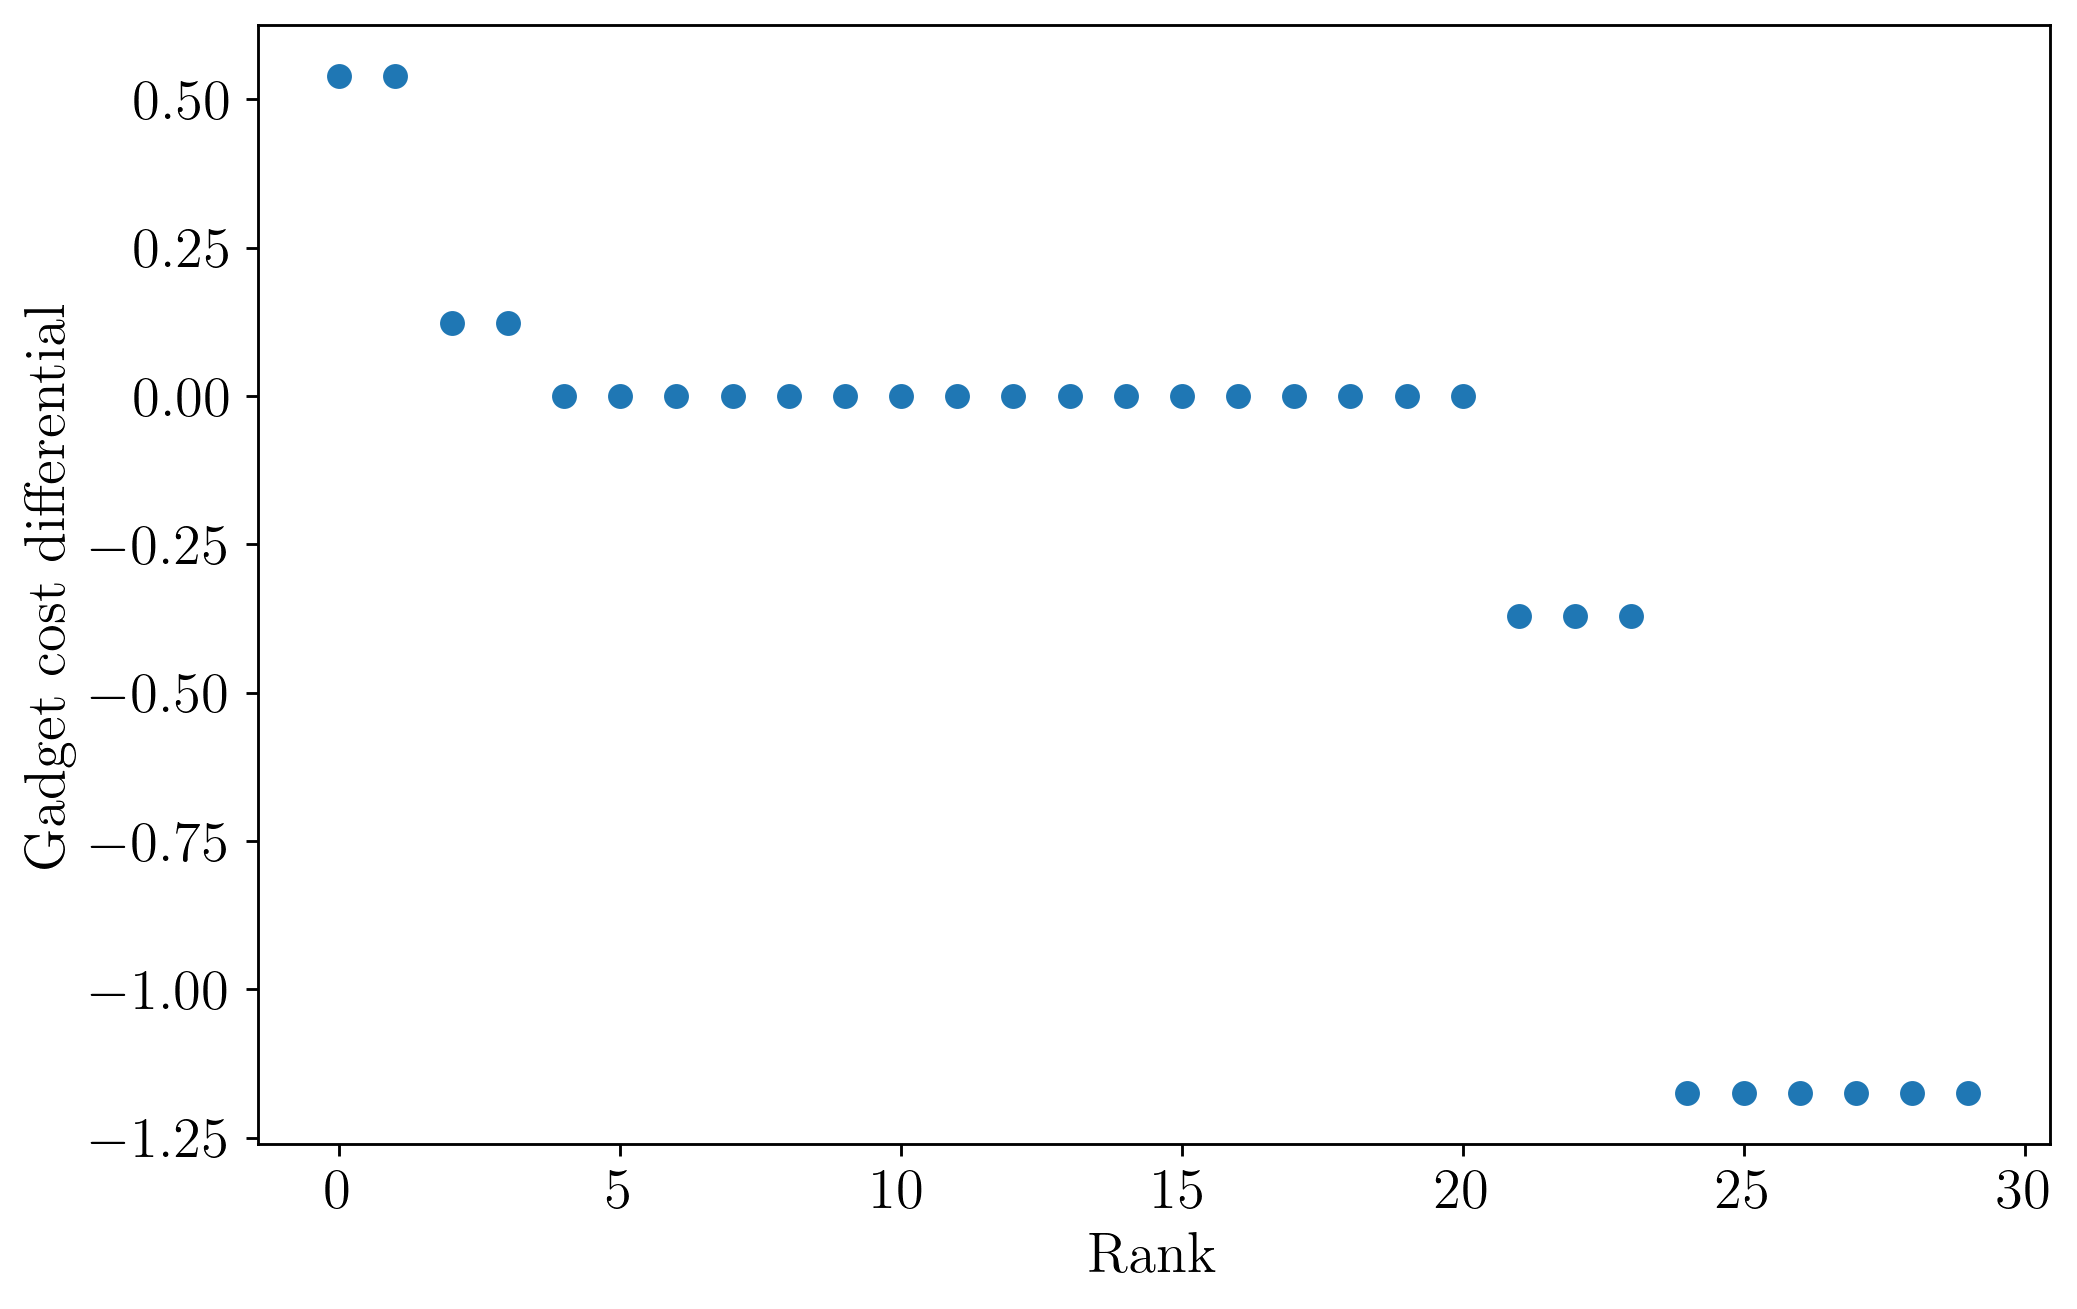

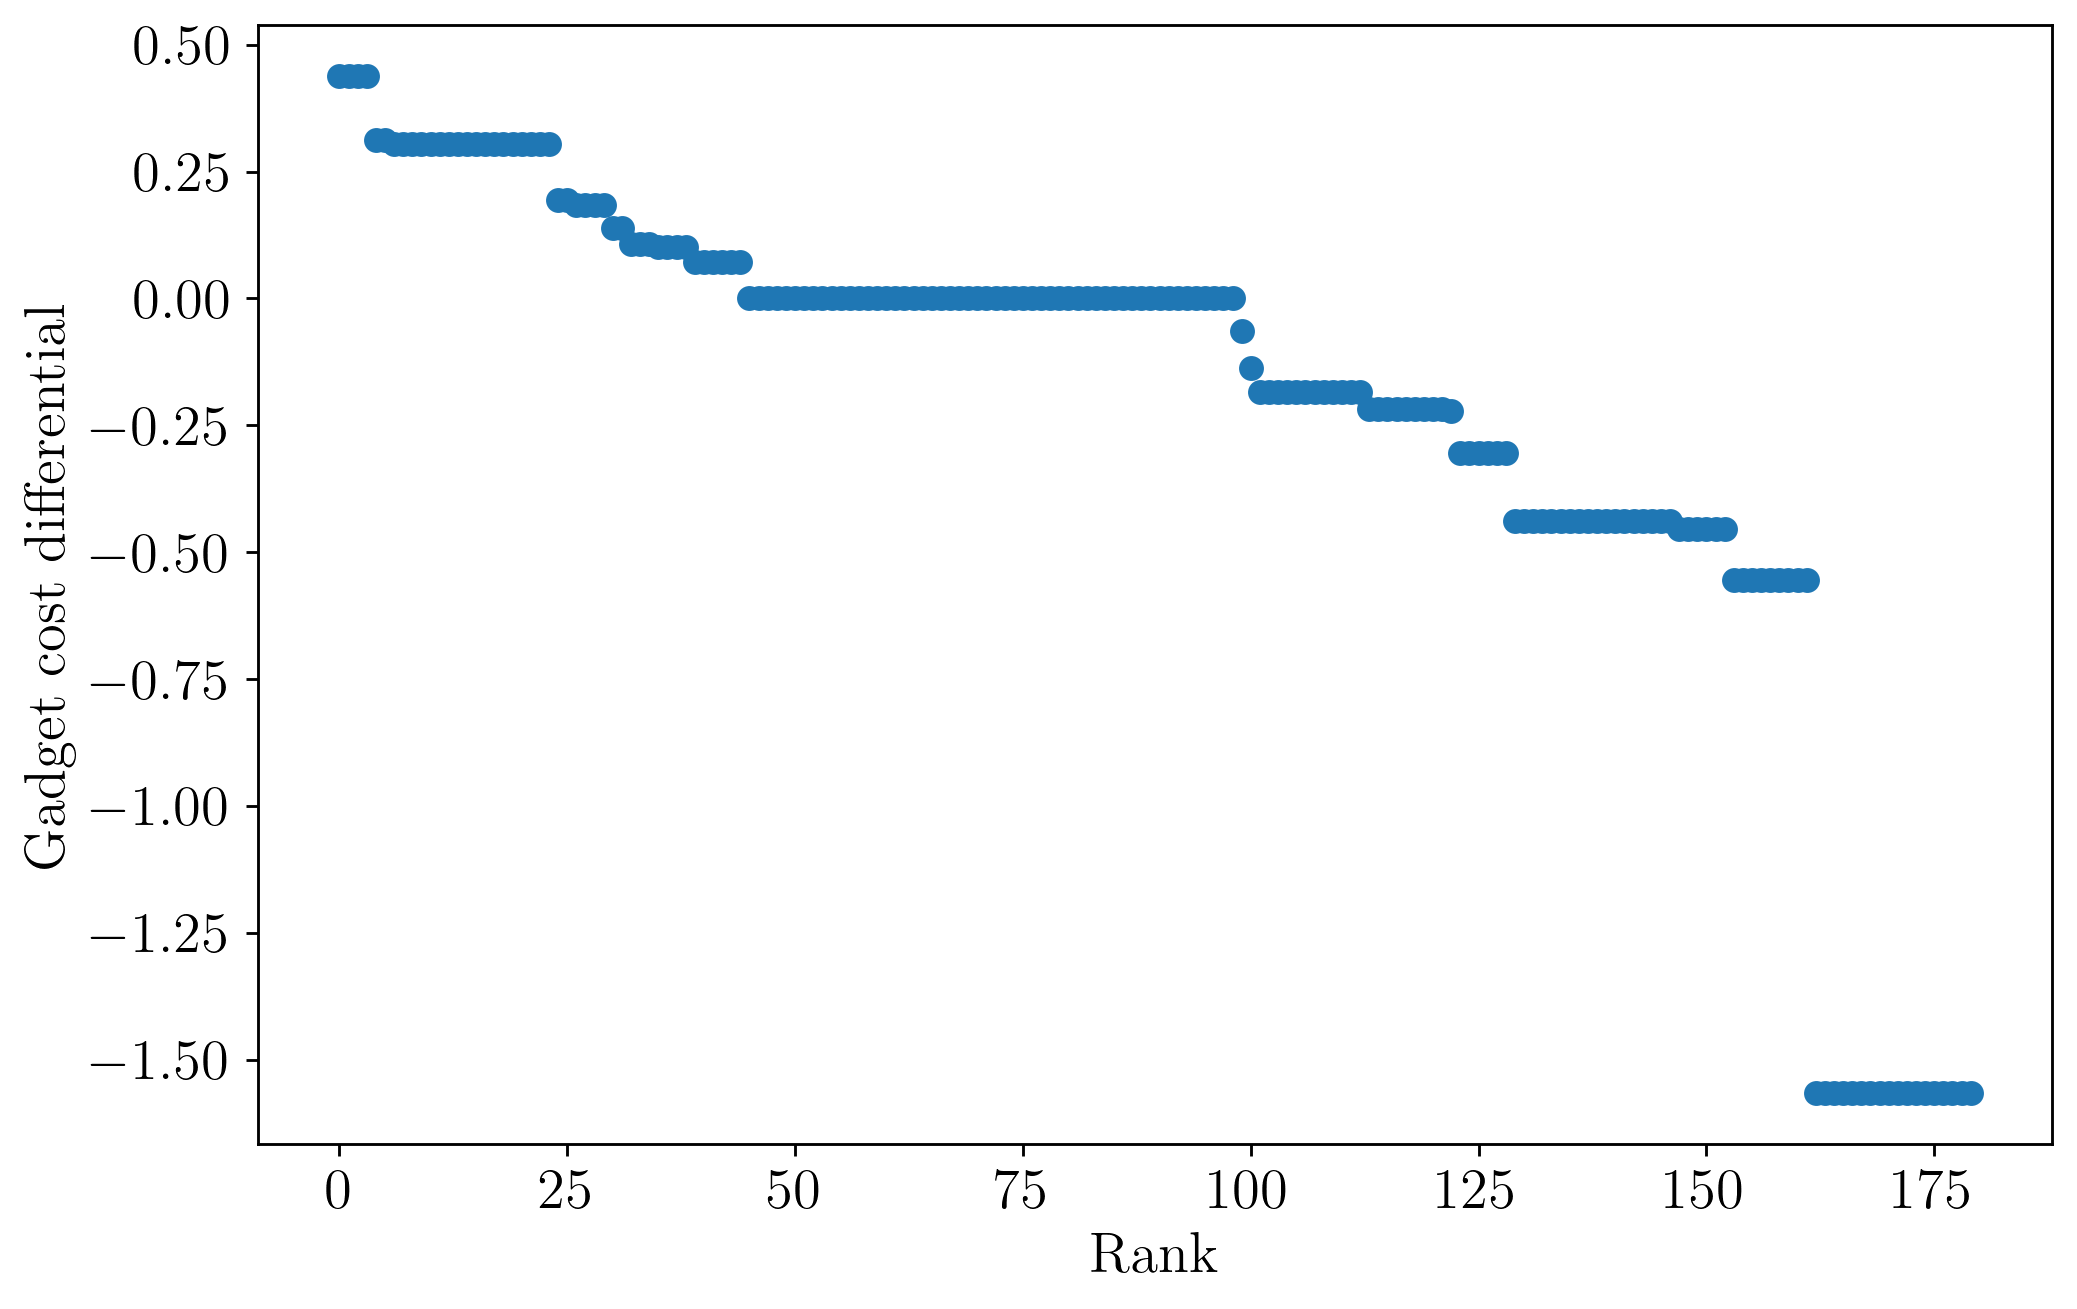

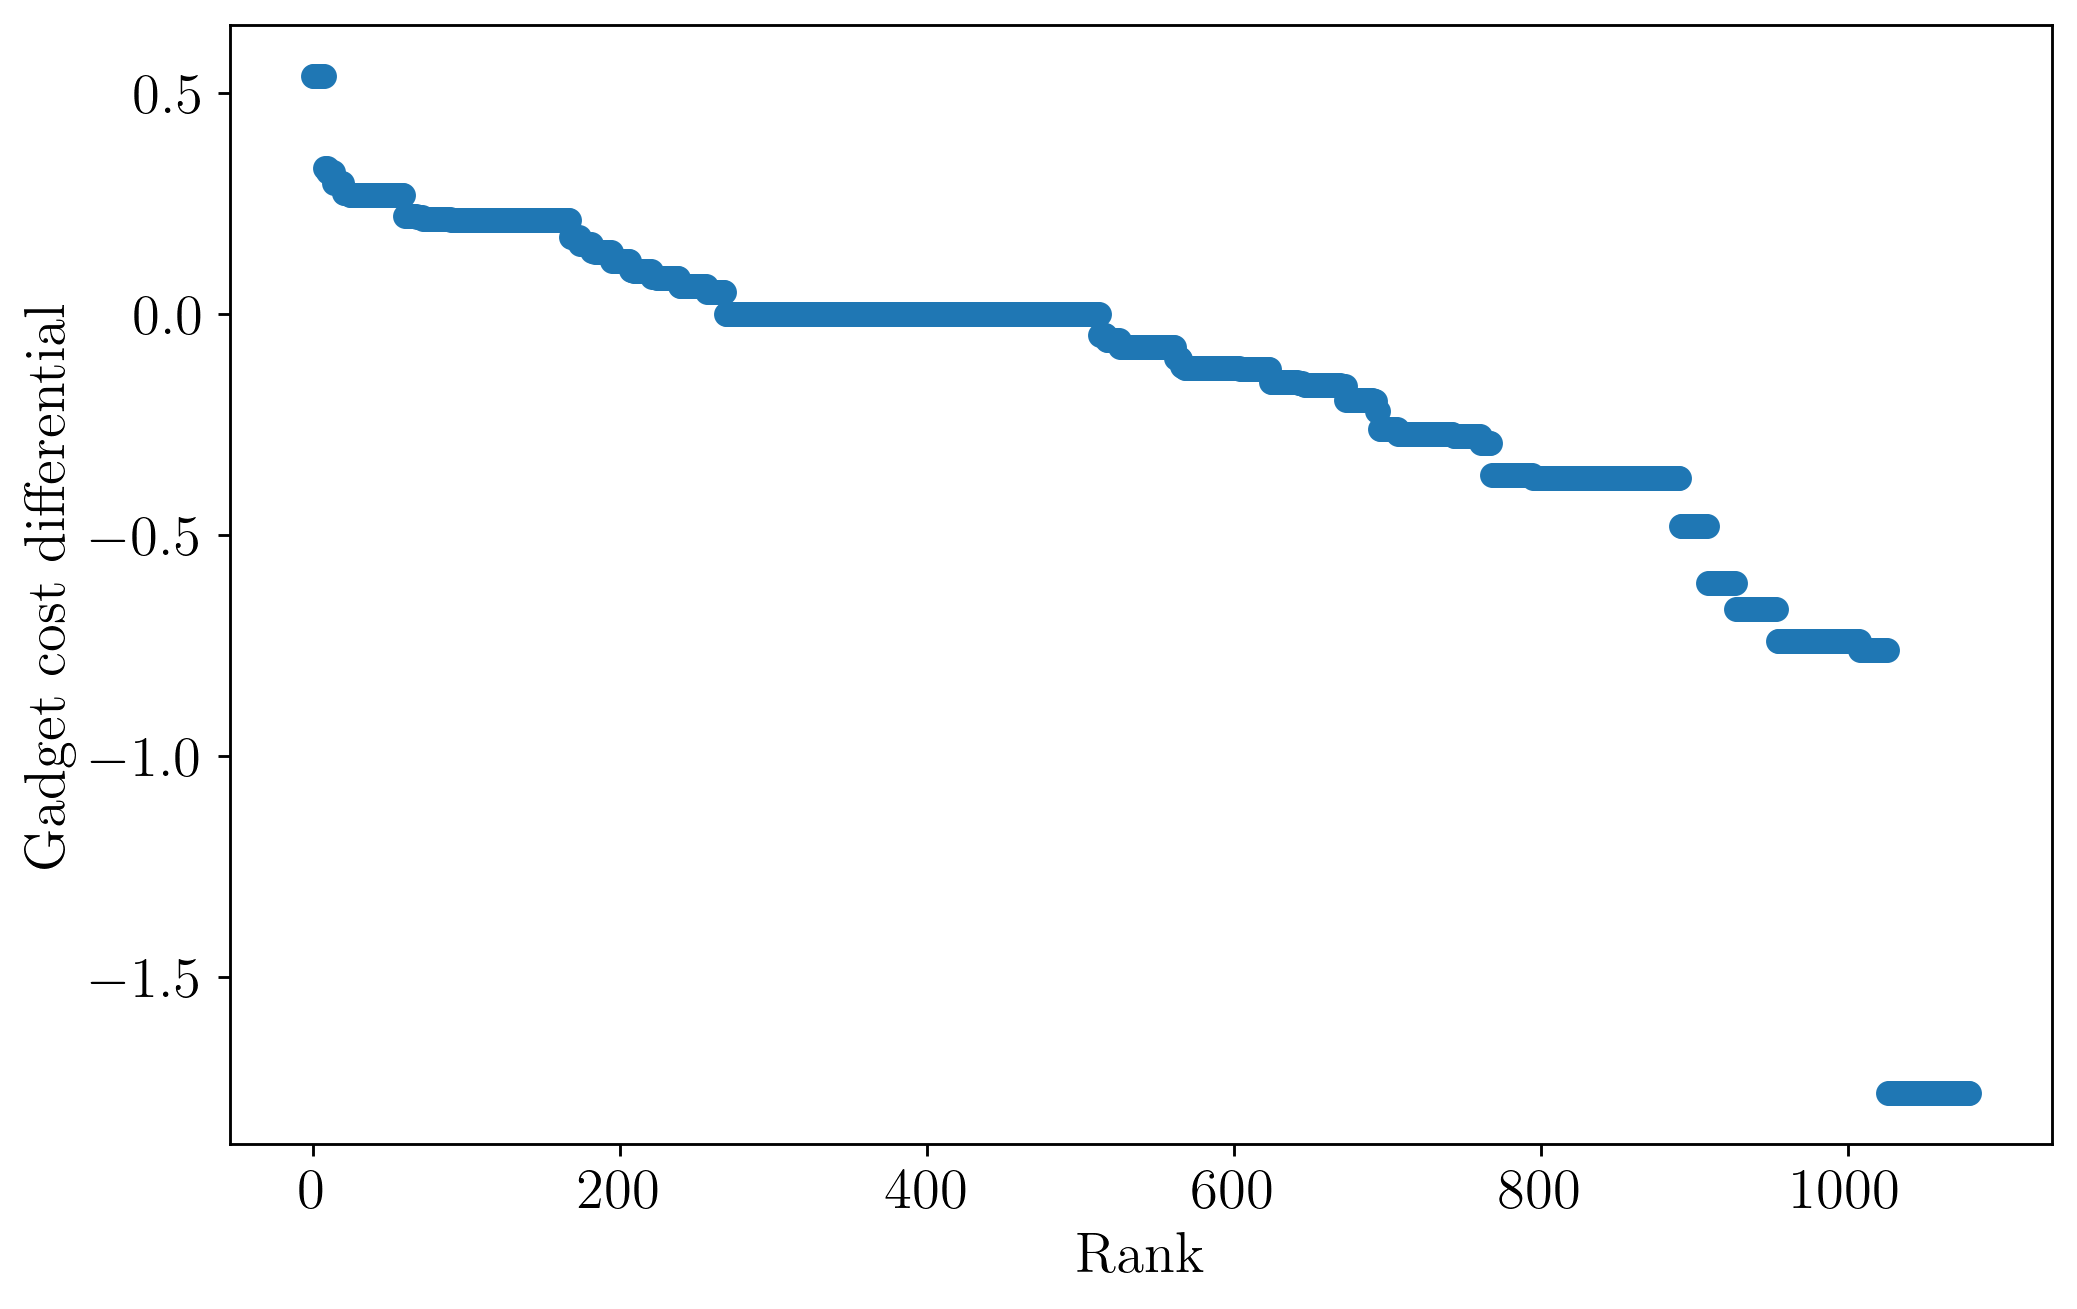

In [21]:
for ka, a in gadget_costs.items():
    for kb, b in a.items():
        # Cost differentials are already normalized by the additive prediction in compute_gadget_costs
        y = sorted(list(b.values()))[::-1]

        x = list(range(len(y)))

        fig, ax = plt.subplots(figsize=(8,5), layout="constrained")
        
        plt.scatter(x, y)

        plt.yscale("linear")

        plt.xlabel("Rank")
        plt.ylabel("Gadget cost differential")
        
        plt.savefig(f"./output/gadget_costs_deeper.png", dpi=256)
        plt.gcf().set_dpi(256)